In [1]:
import whisper
import os 
from tqdm import tqdm

model = whisper.load_model("medium")
input_dir = 'input dir with .mp3 files'
files = os.listdir(input_dir)

res_dict = {}    

for file in tqdm(files):
    if file.endswith(".mp3"):
        input_file = os.path.join(input_dir, file)
        result = model.transcribe(input_file)
        res_dict[f'{file[:19]}'] = result['text']


In [41]:
import pickle

with open('pickle file with transcripts in a dictionary','rb') as handle :
    res_dict = pickle.load(handle)

In [42]:
import pandas as pd
#load the dictionary as dataframe
ct_novtt = pd.DataFrame.from_dict(data=res_dict,orient='index',columns=['voice_to_text']).reset_index()
ct_novtt.columns = ['id_video','voice_to_text']


In [43]:
import nltk
from tqdm import tqdm 
nltk.download('punkt')
nltk.download('words')

#we look for transcription in english, with this code we find if some transcripts are unintelligible

def is_half_in_english_vocab(document):
    # Tokenize the document into words
    words = nltk.word_tokenize(document.lower())

    # Count the number of words in the English vocabulary
    english_vocab = set(nltk.corpus.words.words())
    num_english_words = sum(1 for word in words if word in english_vocab)

    # Check if at least half of the words are in the English vocabulary
    return num_english_words >= len(words) / 2 and len(words) >=10

ct_novtt['makes_sense'] = ct_novtt['voice_to_text'].apply(is_half_in_english_vocab)

[nltk_data] Downloading package punkt to /home/user/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package words to /home/user/nltk_data...
[nltk_data]   Package words is already up-to-date!


In [44]:
tmp = ct_novtt[ct_novtt['makes_sense'] == True]

In [45]:
#sample of 100 videos manually coded, the videos are the same of res_dict
sample_100_w = pd.read_csv('/home/user/whisper_phd/data/raw/df/sample_100_merged_manual - sample_100_merged.csv')

In [55]:
#we merge the two obtained vtt into one df
whisper_vtt = pd.DataFrame(res_dict.items(), columns=['id', 'whisper_cc'])
whisper_vtt['id'] = whisper_vtt['id'].astype(str)
sample_100_w['id'] = sample_100_w['id'].astype(str)
total_vtt = whisper_vtt.merge(right=sample_100_w[['id','voice_to_text']],left_on='id',right_on='id',how='inner')

In [62]:
#cleaning the transcriptions
import string
total_vtt['voice_to_text'] = total_vtt['voice_to_text'].str.lower()
total_vtt['voice_to_text'] = total_vtt['voice_to_text'].str.translate(str.maketrans('', '', string.punctuation))
total_vtt['whisper_cc'] = total_vtt['whisper_cc'].str.lower()
total_vtt['whisper_cc'] = total_vtt['whisper_cc'].str.translate(str.maketrans('', '', string.punctuation))

In [67]:
#calc the score
from jiwer import wer 

total_vtt['wer_score'] = total_vtt.apply(lambda row: wer(row['whisper_cc'],row['voice_to_text']),axis=1)

In [69]:
total_vtt.drop(total_vtt[total_vtt['voice_to_text'] == 'nop'].index,inplace=True)

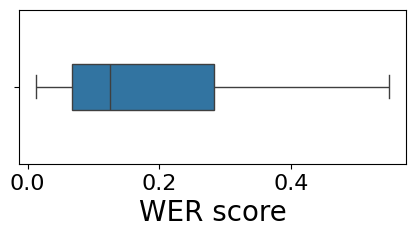

In [71]:
import seaborn as sns
import matplotlib.pyplot as plt
figure = plt.figure(figsize=(5,2))
sns.boxplot(data=total_vtt['wer_score'],width=0.3,showfliers=False,orient='h')
plt.xlabel('WER score')
plt.savefig(f"../img/PR_rq1_wer_score.pdf", format="pdf", bbox_inches="tight")